# Uçtan Uca Yapay Zeka Projesi: Öğrenci Başarı Tahmini

**Soru:** Bir öğrencinin *haftalık çalışma saati*, *günlük uyku süresi* ve *devamsızlık gün sayısı* bilgilerinden, dersi **geçip geçmeyeceğini** tahmin edebilir miyiz?

| | |
|---|---|
| **Hedef değişken (y)** | `gecti` (1 = geçti, 0 = kaldı) |
| **Problem türü** | Sınıflandırma |
| **Araçlar** | Python, Pandas, NumPy, Matplotlib, scikit-learn |

Not defteri, proje envanterindeki 6 aşamayı sırayla izler. Tüm hücreler yukarıdan aşağıya çalıştırılabilir (*Çalışma zamanı → Tümünü çalıştır*).

## Aşama 1 — Problem Tanımı

**Proje Tanım Formu**
- **Problem cümlesi:** Çalışma saati, uyku ve devamsızlık bilgilerinden öğrencinin dersi geçip geçmeyeceğini tahmin et.
- **Hedef değişken:** `gecti`
- **Problem türü:** Sınıflandırma (çıktı bir sayı değil, iki sınıftan biri)

**Gerekçe:** Dönem sonunda kalan öğrencilerin çoğu, dönem ortasında fark edilebilecek işaretler verir: az çalışma, düzensiz uyku, sık devamsızlık. Bu işaretlerden erken bir risk tahmini üretmek, danışman öğretmenin destek gerektiren öğrencilere *not açıklanmadan önce* ulaşmasını sağlar. Öğrenci için de somut bir geri bildirimdir: “devamsızlığını 3 gün azaltırsan risk sınıfından çıkıyorsun” gibi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

plt.rcParams["figure.dpi"] = 110

## Aşama 2 — Veri Toplama ve Hazırlama

Gerçek öğrenci notları kişisel veri olduğu için veri setini **kendimiz oluşturduk** (envanter buna izin veriyor). 60 öğrencilik bir sınıf simüle ettik: geçme olasılığı çalışma ve uykuyla artıp devamsızlıkla azalıyor, üzerine rastgele gürültü ekli — yani ilişki var ama kusursuz değil, tıpkı gerçek hayattaki gibi.

Gerçekçi olsun diye veriye bilerek **eksik değerler** ve bir **hatalı kayıt** (26 saat uyku!) koyduk; bunları aşağıda temizliyoruz.

In [2]:
rng = np.random.default_rng(42)
n = 60

calisma = rng.uniform(0, 20, n).round(1)                 # haftalık çalışma saati
uyku = rng.normal(7, 1.2, n).clip(4, 10).round(1)        # günlük uyku saati
devamsizlik = rng.poisson(5, n).clip(0, 15)              # devamsız gün sayısı

z = 0.45 * calisma - 0.6 * devamsizlik + 0.5 * (uyku - 7) - 1.5 + rng.normal(0, 1.2, n)
gecti = (z > 0).astype(int)

df_ham = pd.DataFrame({"calisma_saati": calisma, "uyku_saati": uyku,
                       "devamsizlik": devamsizlik, "gecti": gecti})

# Gerçek hayattaki kirliliği taklit et: eksik değerler + bir hatalı giriş
df_ham.loc[[5, 17, 33], "uyku_saati"] = np.nan
df_ham.loc[[9, 41], "calisma_saati"] = np.nan
df_ham.loc[22, "uyku_saati"] = 26.0

df_ham.to_csv("ogrenci_verisi.csv", index=False)
print("ogrenci_verisi.csv kaydedildi.")

ogrenci_verisi.csv kaydedildi.


In [3]:
df = pd.read_csv("ogrenci_verisi.csv")
print("Boyut:", df.shape)
df.head()

Boyut: (60, 4)


,calisma_saati,uyku_saati,devamsizlik,gecti
0,15.5,6.0,4,1
1,8.8,8.2,3,1
2,17.2,5.0,6,1
3,13.9,6.6,6,1
4,1.9,7.2,5,0


**Veri sözlüğü**

| Sütun | Tip | Anlamı | Rol |
|---|---|---|---|
| `calisma_saati` | sayısal | Haftalık ders çalışma süresi (saat) | Özellik (X) |
| `uyku_saati` | sayısal | Ortalama günlük uyku (saat) | Özellik (X) |
| `devamsizlik` | sayısal | Dönem içi devamsız gün sayısı | Özellik (X) |
| `gecti` | kategorik (0/1) | Dersi geçti mi? | Hedef (y) |

In [4]:
print("Eksik değer sayıları:")
print(df.isnull().sum())
print()
print("Mantıksız uyku değerleri (>12 saat):")
print(df[df["uyku_saati"] > 12])

Eksik değer sayıları:
calisma_saati    2
uyku_saati       3
devamsizlik      0
gecti            0
dtype: int64

Mantıksız uyku değerleri (>12 saat):
    calisma_saati  uyku_saati  devamsizlik  gecti
22           19.4        26.0            4      1


**Temizleme adımları**
1. 12 saatten uzun uyku fiziksel olarak mümkün değil → hatalı giriş kabul edilip **eksik** (NaN) yapıldı.
2. Eksik değerler satır silinerek değil, sütunun **medyanı** ile dolduruldu (`fillna`). 60 satırlık küçük bir veride 6 satır atmak verinin %10'unu kaybetmek olurdu; medyan da uç değerlerden etkilenmez.

In [5]:
df.loc[df["uyku_saati"] > 12, "uyku_saati"] = np.nan
for sutun in ["calisma_saati", "uyku_saati"]:
    df[sutun] = df[sutun].fillna(df[sutun].median())

print("Temizlik sonrası eksik değer:", int(df.isnull().sum().sum()))
print("Boyut:", df.shape)

Temizlik sonrası eksik değer: 0
Boyut: (60, 4)


## Aşama 3 — Keşifçi Veri Analizi (EDA)

In [6]:
df.describe().round(2)

,calisma_saati,uyku_saati,devamsizlik,gecti
count,60.00,60.00,60.00,60.00
mean,10.31,6.70,4.92,0.55
std,5.61,0.88,1.99,0.50
min,0.10,4.90,1.00,0.00
25%,5.48,6.15,3.00,0.00
50%,10.30,6.60,5.00,1.00
75%,15.27,7.35,6.25,1.00
max,19.50,8.60,11.00,1.00


In [7]:
print("Sınıf dağılımı:")
print(df["gecti"].value_counts().rename({1: "geçti", 0: "kaldı"}))
print()
print("Geçen ve kalanların ortalamaları:")
df.groupby("gecti")[["calisma_saati", "uyku_saati", "devamsizlik"]].mean().round(2).rename(index={0: "kaldı", 1: "geçti"})

Sınıf dağılımı:
gecti
geçti    33
kaldı    27
Name: count, dtype: int64

Geçen ve kalanların ortalamaları:


,calisma_saati,uyku_saati,devamsizlik
gecti,,,
kaldı,6.05,6.69,5.78
geçti,13.80,6.71,4.21


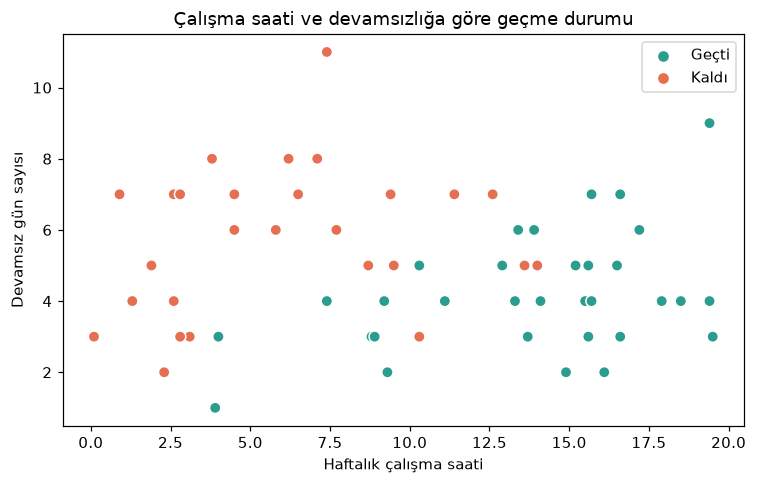

In [8]:
renk = df["gecti"].map({1: "#2a9d8f", 0: "#e76f51"})
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["calisma_saati"], df["devamsizlik"], c=renk, s=55, edgecolor="white")
ax.scatter([], [], c="#2a9d8f", label="Geçti")
ax.scatter([], [], c="#e76f51", label="Kaldı")
ax.set_title("Çalışma saati ve devamsızlığa göre geçme durumu")
ax.set_xlabel("Haftalık çalışma saati")
ax.set_ylabel("Devamsız gün sayısı")
ax.legend()
plt.tight_layout()
plt.savefig("grafik_dagilim.png", dpi=200)
plt.show()

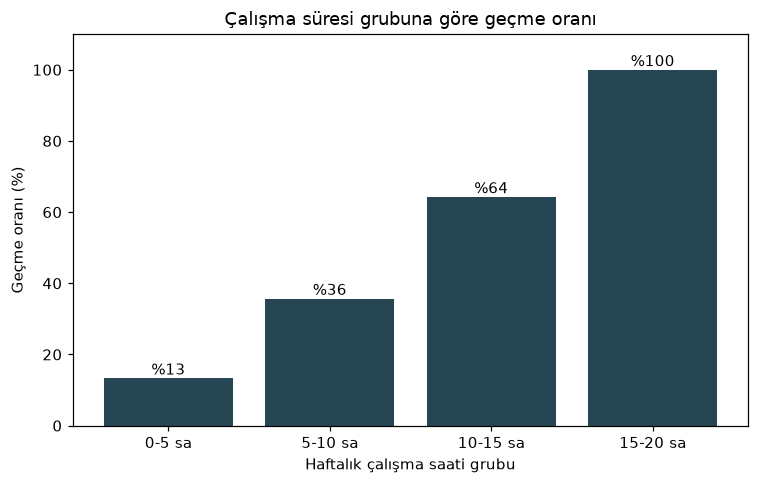

In [9]:
df["calisma_grubu"] = pd.cut(df["calisma_saati"], bins=[0, 5, 10, 15, 20],
                             labels=["0-5 sa", "5-10 sa", "10-15 sa", "15-20 sa"], include_lowest=True)
oran = df.groupby("calisma_grubu", observed=True)["gecti"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
cubuklar = ax.bar(oran.index.astype(str), oran.values, color="#264653")
ax.bar_label(cubuklar, fmt="%%%.0f")
ax.set_title("Çalışma süresi grubuna göre geçme oranı")
ax.set_xlabel("Haftalık çalışma saati grubu")
ax.set_ylabel("Geçme oranı (%)")
ax.set_ylim(0, 110)
plt.tight_layout()
plt.savefig("grafik_gecme_orani.png", dpi=200)
plt.show()
df = df.drop(columns="calisma_grubu")

**Keşif bulguları**
1. **Çalışma saati açık ara en belirleyici özellik.** Geçenler haftada ortalama 13,8 saat, kalanlar 6,1 saat çalışıyor. Çubuk grafikte geçme oranı %13 → %36 → %64 → %100 diye düzenli artıyor.
2. **Devamsızlık ters yönde etkili ama daha zayıf.** Kalanların ortalama devamsızlığı 5,8 gün, geçenlerin 4,2 gün.
3. **Uyku tek başına ayırt edici değil.** İki grubun uyku ortalaması neredeyse aynı (6,7 saat).
4. **Sınırda bir bölge var.** 7–14 saat çalışma aralığında yeşil ve kırmızı noktalar iç içe; model en çok burada hata yapacak.
5. **Sınıflar yaklaşık dengeli** (33 geçti / 27 kaldı), bu yüzden doğruluk (accuracy) uygun bir başarı ölçüsü.

## Aşama 4 — Model Kurma ve Eğitme

In [10]:
X = df[["calisma_saati", "uyku_saati", "devamsizlik"]]
y = df["gecti"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print("Eğitim:", X_train.shape, "  Test:", X_test.shape)

Eğitim: (45, 3)   Test: (15, 3)


**Model seçimi: Karar Ağacı (`DecisionTreeClassifier`)**

Hedefimiz iki sınıflı olduğu için sınıflandırma modeli gerekiyor. Karar ağacı “çalışma saati 8,75'ten az **ve** devamsızlık 4'ten fazlaysa → kalır” gibi, öğretmene doğrudan anlatılabilecek kurallar üretir. Sınırsız bir ağaç 45 satırı ezberler (aşırı öğrenme), bu yüzden ağacın **derinliğini sınırlıyoruz**. Hangi derinliğin en iyi olduğunu test verisine bakarak değil, yalnızca eğitim verisi üzerinde **5 katlı çapraz doğrulama** ile seçiyoruz — test verisi en sona, tarafsız ölçüm için saklanıyor.

In [11]:
for derinlik in range(1, 6):
    puan = cross_val_score(DecisionTreeClassifier(max_depth=derinlik, random_state=42),
                           X_train, y_train, cv=5).mean()
    print(f"max_depth={derinlik}: çapraz doğrulama doğruluğu %{puan*100:.1f}")

max_depth=1: çapraz doğrulama doğruluğu %80.0
max_depth=2: çapraz doğrulama doğruluğu %80.0
max_depth=3: çapraz doğrulama doğruluğu %80.0
max_depth=4: çapraz doğrulama doğruluğu %82.2
max_depth=5: çapraz doğrulama doğruluğu %82.2


In [12]:
EN_IYI_DERINLIK = max(range(1, 6), key=lambda d: cross_val_score(
    DecisionTreeClassifier(max_depth=d, random_state=42), X_train, y_train, cv=5).mean())

model = DecisionTreeClassifier(max_depth=EN_IYI_DERINLIK, random_state=42)
model.fit(X_train, y_train)
print(f"Model eğitildi (max_depth={EN_IYI_DERINLIK}).")

Model eğitildi (max_depth=4).


## Aşama 5 — Tahmin ve Değerlendirme

In [13]:
y_tahmin = model.predict(X_test)
test_dogruluk = accuracy_score(y_test, y_tahmin)
egitim_dogruluk = model.score(X_train, y_train)
taban = y_test.value_counts(normalize=True).max()   # hep çoğunluk sınıfını söyleyen "tembel" model

print(f"Test doğruluğu      : %{test_dogruluk*100:.1f}")
print(f"Eğitim doğruluğu    : %{egitim_dogruluk*100:.1f}")
print(f"Taban çizgisi       : %{taban*100:.1f}  (hep çoğunluk sınıfını tahmin etmek)")
cv_tum = cross_val_score(DecisionTreeClassifier(max_depth=EN_IYI_DERINLIK, random_state=42), X, y, cv=5)
print(f"5 katlı ÇD (60 satır): %{cv_tum.mean()*100:.1f} ± {cv_tum.std()*100:.1f}  (daha kararlı ölçü)")
print()
print("Karışıklık matrisi (satır = gerçek, sütun = tahmin; 0 = kaldı, 1 = geçti):")
print(confusion_matrix(y_test, y_tahmin))

Test doğruluğu      : %66.7
Eğitim doğruluğu    : %97.8
Taban çizgisi       : %53.3  (hep çoğunluk sınıfını tahmin etmek)
5 katlı ÇD (60 satır): %78.3 ± 6.7  (daha kararlı ölçü)

Karışıklık matrisi (satır = gerçek, sütun = tahmin; 0 = kaldı, 1 = geçti):
[[4 3]
 [2 6]]


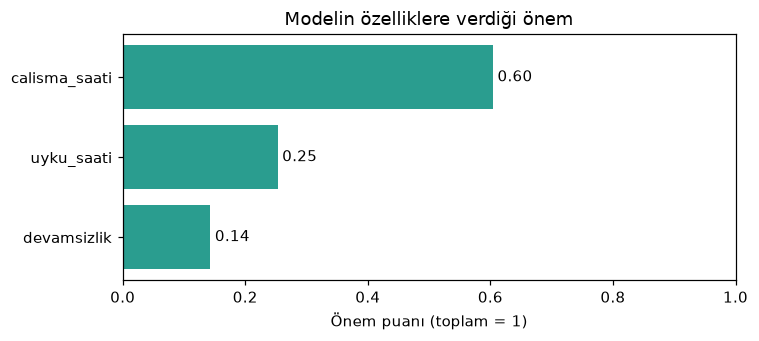

In [14]:
onem = pd.Series(model.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
cubuklar = ax.barh(onem.index, onem.values, color="#2a9d8f")
ax.bar_label(cubuklar, fmt="%.2f", padding=3)
ax.set_title("Modelin özelliklere verdiği önem")
ax.set_xlabel("Önem puanı (toplam = 1)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig("grafik_ozellik_onemi.png", dpi=200)
plt.show()

In [15]:
yeni = pd.DataFrame({
    "calisma_saati": [15, 4, 9, 12],
    "uyku_saati":    [7.5, 6, 7, 5],
    "devamsizlik":   [2, 9, 5, 1],
})
olasilik = model.predict_proba(yeni)[:, 1] * 100
yeni["tahmin"] = np.where(olasilik >= 50, "Geçer", "Kalır")
yeni["geçme olasılığı"] = [f"%{p:.0f}" for p in olasilik]
yeni

,calisma_saati,uyku_saati,devamsizlik,tahmin,geçme olasılığı
0,15,7.5,2,Geçer,%100
1,4,6.0,9,Kalır,%0
2,9,7.0,5,Geçer,%100
3,12,5.0,1,Geçer,%100


**Değerlendirme notu — model güvenilir mi?**

- **Kısmen.** 60 öğrencinin tamamı üzerinde 5 katlı çapraz doğrulama ~%78 doğruluk veriyor; hep çoğunluk sınıfını söyleyen taban çizgisi ise %53–55. Model gerçekten bir şey öğrenmiş.
- **Ayrı tutulan 15 kişilik test kümesinde doğruluk %66,7** (15'te 10 doğru). Test kümesi o kadar küçük ki tek bir yanlış tahmin sonucu ~7 puan oynatıyor; bu yüzden daha kararlı ölçü olarak çapraz doğrulamayı esas alıyoruz.
- **Aşırı öğrenme işareti var:** eğitim doğruluğu %97,8, test %66,7. Derinlik 4'teki ağaç küçük gruplar için kurallar ezberlemiş; olasılıkların hep %0 ya da %100 çıkması da bunun belirtisi.
- **Uykuya verilen 0,25'lik önem büyük olasılıkla gürültü:** EDA'da uyku iki grupta aynıydı. Ağaç, çalışkan öğrencilerin içindeki birkaç istisnayı uyku üzerinden ayırmaya çalışmış.
- **İyileştirme fikirleri:** daha büyük ve gerçek veri toplamak; eşit puanlı derinlikler arasında daha basit ağacı seçmek; ara sınav notu gibi güçlü bir özellik eklemek; lojistik regresyonla karşılaştırmak.

## Aşama 6 — Akıllı Tahmin Aracı (Mini Uygulama)

In [16]:
def tahmin_et(calisma_saati, uyku_saati, devamsizlik):
    """Öğrenci bilgilerini alır, okunur bir tahmin cümlesi döndürür."""
    girdi = pd.DataFrame([[calisma_saati, uyku_saati, devamsizlik]], columns=X.columns)
    olasilik = model.predict_proba(girdi)[0, 1] * 100
    if olasilik >= 50:
        return f"Tahmin: GEÇER ✅ (geçme olasılığı %{olasilik:.0f}). Bu tempoyu koru!"
    return (f"Tahmin: RİSKLİ ⚠️ (geçme olasılığı %{olasilik:.0f}). "
            f"Haftalık çalışmayı artırmak ve devamsızlığı azaltmak riski düşürür.")

print(tahmin_et(15, 7.5, 2))
print(tahmin_et(4, 6, 9))

Tahmin: GEÇER ✅ (geçme olasılığı %100). Bu tempoyu koru!
Tahmin: RİSKLİ ⚠️ (geçme olasılığı %0). Haftalık çalışmayı artırmak ve devamsızlığı azaltmak riski düşürür.


In [17]:
# Kendi bilgilerini gir ve anında tahmin al
try:
    c = float(input("Haftalık çalışma saatin: "))
    u = float(input("Günlük ortalama uyku saatin: "))
    d = int(input("Devamsız gün sayın: "))
except Exception:
    # Etkileşimsiz ortamda (ör. otomatik çalıştırma) örnek değerlerle devam et
    c, u, d = 8, 7, 4
    print(f"(Örnek girdi kullanıldı: çalışma={c}, uyku={u}, devamsızlık={d})")
print(tahmin_et(c, u, d))

(Örnek girdi kullanıldı: çalışma=8, uyku=7, devamsızlık=4)
Tahmin: GEÇER ✅ (geçme olasılığı %100). Bu tempoyu koru!


## Sonuç

- Üç basit bilgiden (çalışma, uyku, devamsızlık) öğrencinin dersi geçip geçmeyeceğini **~%78 doğrulukla** (çapraz doğrulama) tahmin eden, çalışan bir model kurduk; tahmin yapmayan taban çizgisi %55.
- En belirleyici etken **haftalık çalışma saati**: 15 saatin üzerinde çalışanların tamamı geçmiş. Devamsızlık ikinci sırada; uyku tek başına zayıf.
- Model eğitim verisini kısmen ezberliyor; veri küçük ve simüle olduğu için sonuçlar bir **kavram kanıtı**. Gerçek bir sınıfta kullanmadan önce gerçek veriyle yeniden eğitilmeli.
- `tahmin_et()` fonksiyonu modeli, kullanıcıya anlamlı bir cümleyle cevap veren mini bir uygulamaya dönüştürüyor.